# Brain Tumor Detection Using MRI Images

## Project Overview
This project applies deep learning to brain MRI images to classify them into the dataset's tumor categories. It explores two approaches: a custom Convolutional Neural Network (CNN) and transfer learning with ResNet50. The models are evaluated on a separate testing dataset, and Grad-CAM is used to visualize image regions that influence ResNet50 predictions.

In [11]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Path to dataset files: /kaggle/input/brain-tumor-mri-dataset


In [12]:
path

'/kaggle/input/brain-tumor-mri-dataset'

In [13]:
import os
import kagglehub

# Download dataset and get its actual path
path = kagglehub.dataset_download(
    "masoudnickparvar/brain-tumor-mri-dataset"
)

print("Dataset path:", path)
print("Path exists:", os.path.exists(path))

# Find Training and Testing folders
for root, dirs, files in os.walk(path):
    if "Training" in dirs and "Testing" in dirs:
        train_dir = os.path.join(root, "Training")
        test_dir = os.path.join(root, "Testing")
        break
else:
    raise FileNotFoundError(
        f"Training and Testing folders not found in: {path}"
    )

classes = sorted(
    d for d in os.listdir(train_dir)
    if os.path.isdir(os.path.join(train_dir, d))
)

print("Training directory:", train_dir)
print("Testing directory:", test_dir)
print("Classes:", classes)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Dataset path: /kaggle/input/brain-tumor-mri-dataset
Path exists: True
Training directory: /kaggle/input/brain-tumor-mri-dataset/Training
Testing directory: /kaggle/input/brain-tumor-mri-dataset/Testing
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


## 1. Libraries and Configuration

Import the libraries used for data handling, visualization, and deep learning. The image size, batch size, and random seed are also defined for the data pipeline.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

In [15]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

## 2. Dataset Preparation

Load the MRI image paths and their class labels from the training folders. Split the available training images into training and validation sets while preserving the class distribution, then resize images to the configured dimensions.

In [16]:

# Training Dataset
from sklearn.model_selection import train_test_split

image_paths = []
image_labels = []

for label, class_name in enumerate(sorted(os.listdir(train_dir))):
    class_dir = os.path.join(train_dir, class_name)

    if not os.path.isdir(class_dir):
        continue

    for filename in os.listdir(class_dir):
        if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
            image_paths.append(os.path.join(class_dir, filename))
            image_labels.append(label)

train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths,
    image_labels,
    test_size=0.2,
    random_state=SEED,
    stratify=image_labels
)

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_ds = train_ds.shuffle(len(train_paths), seed=SEED)
train_ds = train_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.batch(BATCH_SIZE)


In [17]:
# Check Dataset Split
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))

print("\nTraining classes:")
print(np.bincount(train_labels))

print("\nValidation classes:")
print(np.bincount(val_labels))

Training images: 4480
Validation images: 1120

Training classes:
[1120 1120 1120 1120]

Validation classes:
[280 280 280 280]


### Validation Dataset

Create the validation dataset from the images reserved during the training split. It is used to monitor model performance during training.

In [18]:

# Validation Dataset
val_ds = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_ds = val_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE)

### Testing Dataset

Inspect the number of images in the independent testing folders before creating the test dataset.

In [19]:
import os

print("Training:", len(train_paths))
print("Validation:", len(val_paths))

test_count = sum(
    len([
        f for f in os.listdir(os.path.join(test_dir, class_name))
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ])
    for class_name in os.listdir(test_dir)
    if os.path.isdir(os.path.join(test_dir, class_name))
)

print("Testing:", test_count)

Training: 4480
Validation: 1120
Testing: 1600


### Create the Testing Dataset

Load the testing images from their class folders. This dataset is kept separate from training and validation for final model evaluation.

In [20]:
# Testing Dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

Found 1600 files belonging to 4 classes.


### Class Information

Set the class names and determine the number of output classes from the dataset folders.

In [21]:
class_names = classes
num_class = len(class_names)

print(class_names)
print("Number of classes:", num_class)

['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4


### Dataset Performance Setup

Use TensorFlow prefetching to prepare batches efficiently while the model is running.

In [22]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)


In [23]:
print("Classes:", class_names)
print("Number of classes:", num_class)

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4


## 3. Dataset Visualization

Display sample MRI images from the training, testing, and validation datasets to inspect the image data and class labels.

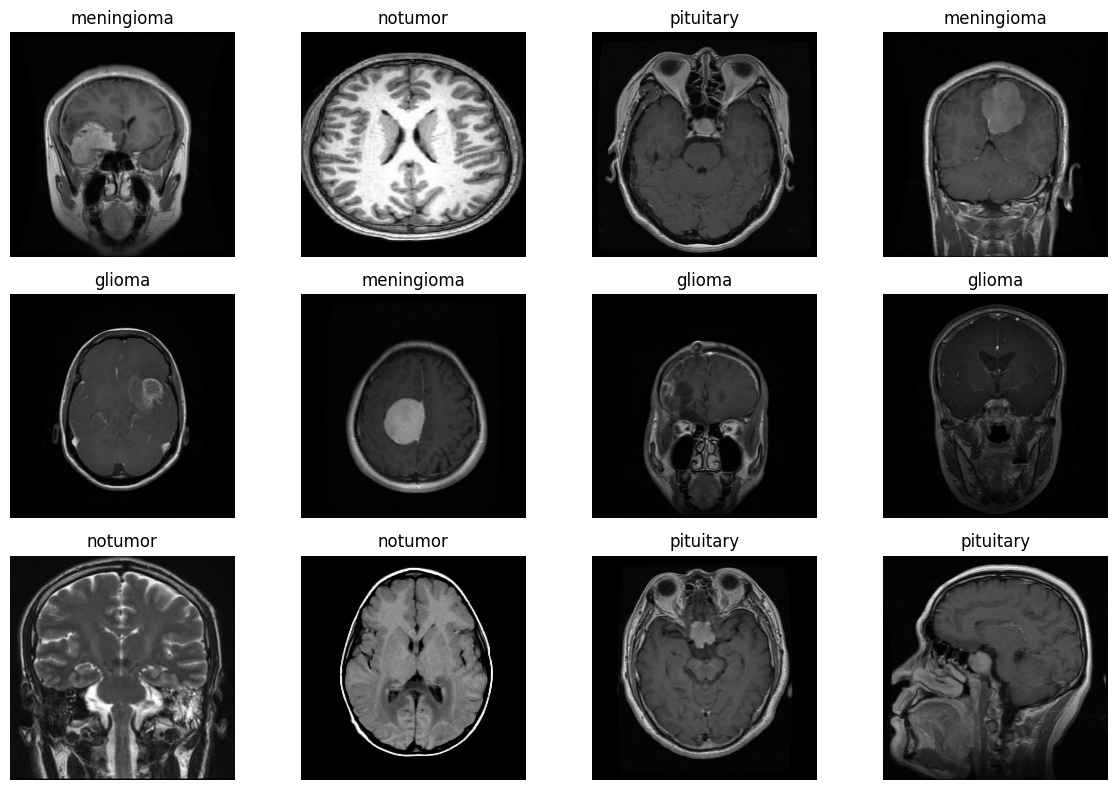

In [24]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i].numpy())])
        plt.axis("off")

plt.tight_layout()
plt.show()


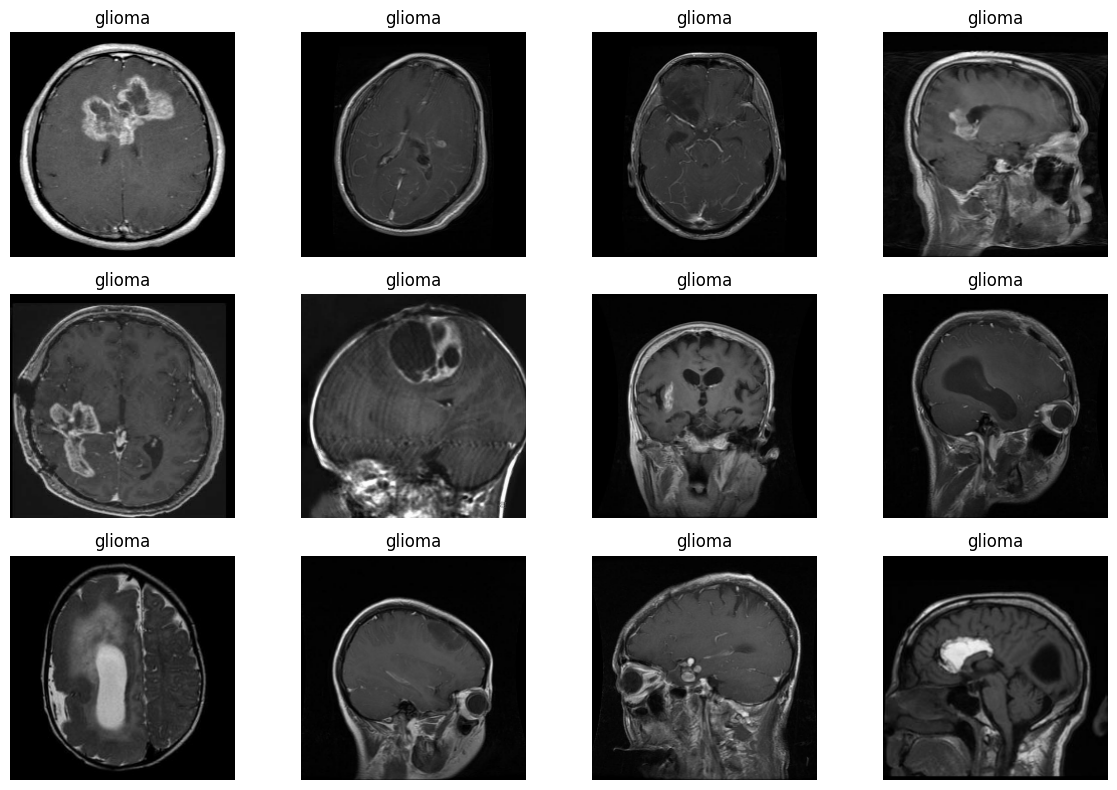

In [25]:
plt.figure(figsize=(12, 8))

for images, labels in test_ds.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i].numpy())])
        plt.axis("off")

plt.tight_layout()
plt.show()


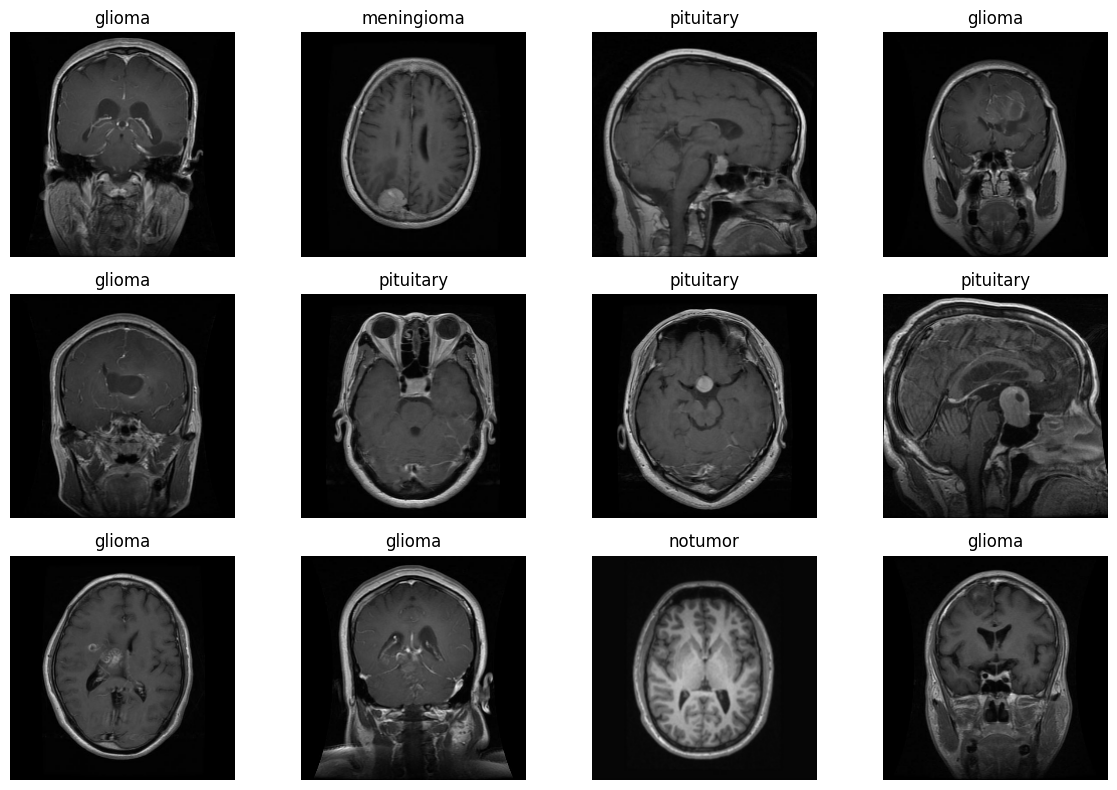

In [26]:
plt.figure(figsize=(12, 8))

for images, labels in val_ds.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i].numpy())])
        plt.axis("off")

plt.tight_layout()
plt.show()


In [27]:
print(class_names)

['glioma', 'meningioma', 'notumor', 'pituitary']


## 4. CNN Model

Build a custom Convolutional Neural Network using convolution and pooling layers to learn image features, followed by dense layers for multi-class classification.

In [28]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras import Sequential

In [29]:
cnn_model = Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu", strides=(1,1), padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", strides=(1,1), padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", strides=(1,1), padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.5),

    layers.Dense(num_class, activation="softmax")
])

### CNN Architecture Summary

Review the CNN model architecture and the number of parameters in each layer.

In [30]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,788 (432.77 KB)

 Trainable params: 110,532 (431.77 KB)

 Non-trainable params: 256 (1.00 KB)

### Compile the CNN Model

Configure the CNN with the Adam optimizer, sparse categorical cross-entropy loss, and accuracy as the training metric.

In [31]:
cnn_model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

### Training Callbacks

Set up callbacks to monitor validation loss, restore the best weights, save the best model checkpoint, and reduce the learning rate when progress stalls.

In [32]:
# Early Stopping
Early = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    mode="auto",
    restore_best_weights=True
)

# Save the best model
Model_check = tf.keras.callbacks.ModelCheckpoint(
    "best_cnn_model.keras",
    monitor="val_loss",
    verbose=0,
    save_best_only=True,
    save_weights_only=False,
    mode="auto"
)

# Reduce Learning Rate
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.1,
    patience=2,
    cooldown=2,
    min_lr=1e-7,
    verbose=1
)

### Train the CNN Model

Train the CNN using the training dataset and monitor its performance on the validation dataset.

In [33]:
history_cnn = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[Early, Model_check, reduce_lr]
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 33s 163ms/step - accuracy: 0.6176 - loss: 0.9315 - val_accuracy: 0.3839 - val_loss: 1.2798 - learning_rate: 0.0010
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 9s 66ms/step - accuracy: 0.7074 - loss: 0.7359 - val_accuracy: 0.6000 - val_loss: 1.0977 - learning_rate: 0.0010
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.7449 - loss: 0.6645 - val_accuracy: 0.6491 - val_loss: 0.8934 - learning_rate: 0.0010
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 78ms/step - accuracy: 0.7696 - loss: 0.6066 - val_accuracy: 0.5670 - val_loss: 0.9499 - learning_rate: 0.0010
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.7794 - loss: 0.5890
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.00010000000474974513.
140/140 ━━━━━━━━━━━━━━━━━━━━ 9s 66ms/step - accuracy: 0.7853 - loss: 0.5730 - val_accuracy: 0.5777 - val_loss: 0.9621 - learning_rate: 0.0010
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 9s 67ms/step - accuracy: 0.8143 - loss

### Class Distribution Check

Count the class labels in the datasets to inspect how the images are distributed across the available categories.

In [34]:
import numpy as np

def count_labels(dataset, name):
    all_labels = np.concatenate([
        labels.numpy() for _, labels in dataset
    ])

    counts = np.bincount(all_labels, minlength=4)

    print(f"\n{name}:")
    for i, class_name in enumerate(class_names):
        print(f"{class_name}: {counts[i]}")

count_labels(train_ds, "Training")
count_labels(val_ds, "Validation")
count_labels(test_ds, "Testing")


Training:
glioma: 1120
meningioma: 1120
notumor: 1120
pituitary: 1120

Validation:
glioma: 280
meningioma: 280
notumor: 280
pituitary: 280

Testing:
glioma: 400
meningioma: 400
notumor: 400
pituitary: 400


### CNN Training History

Plot training and validation accuracy and loss across epochs to observe the model's learning behavior.

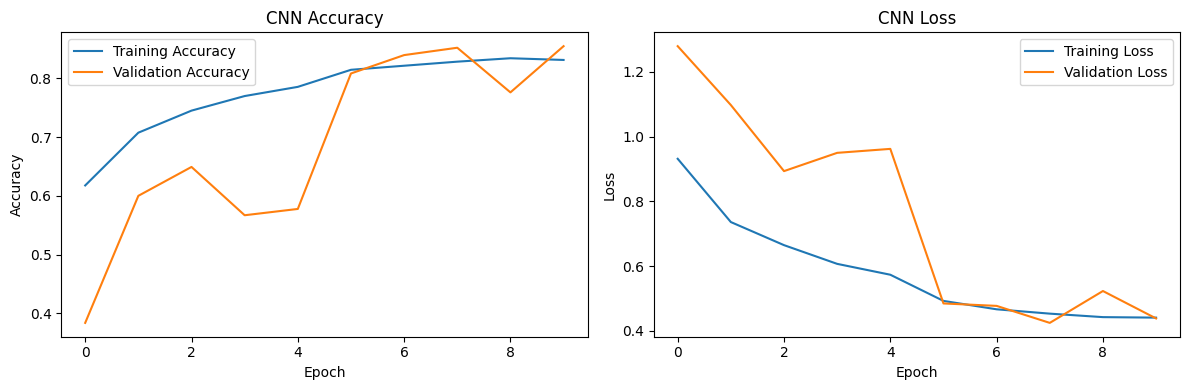

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["loss"], label="Training Loss")
plt.plot(history_cnn.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

### Evaluation Metrics

Import the classification metrics used to assess model predictions, including the classification report and confusion matrix.

In [36]:
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score, accuracy_score

## 5. CNN Model Evaluation

Evaluate the trained CNN on the independent testing dataset and report its test loss and accuracy.

In [37]:
# CNN Evaluation
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(test_ds)

print("CNN Test Accuracy:", cnn_test_accuracy)
print("CNN Test Loss:", cnn_test_loss)

50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.7613 - loss: 0.7785
CNN Test Accuracy: 0.7612500190734863
CNN Test Loss: 0.7784565687179565


### Generate CNN Predictions

Collect the true test labels and generate predicted classes using the trained CNN.

In [38]:

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_pred = np.argmax(cnn_model.predict(test_ds), axis=1)

50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step


### CNN Classification Report

Review precision, recall, F1-score, and support for each class.

In [39]:
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

      glioma       0.83      0.60      0.70       400
  meningioma       0.63      0.61      0.62       400
     notumor       0.76      0.99      0.86       400
   pituitary       0.85      0.83      0.84       400

    accuracy                           0.76      1600
   macro avg       0.77      0.76      0.76      1600
weighted avg       0.77      0.76      0.76      1600



### CNN Confusion Matrix

Visualize the CNN predictions against the true labels to inspect correct and incorrect classifications by class.

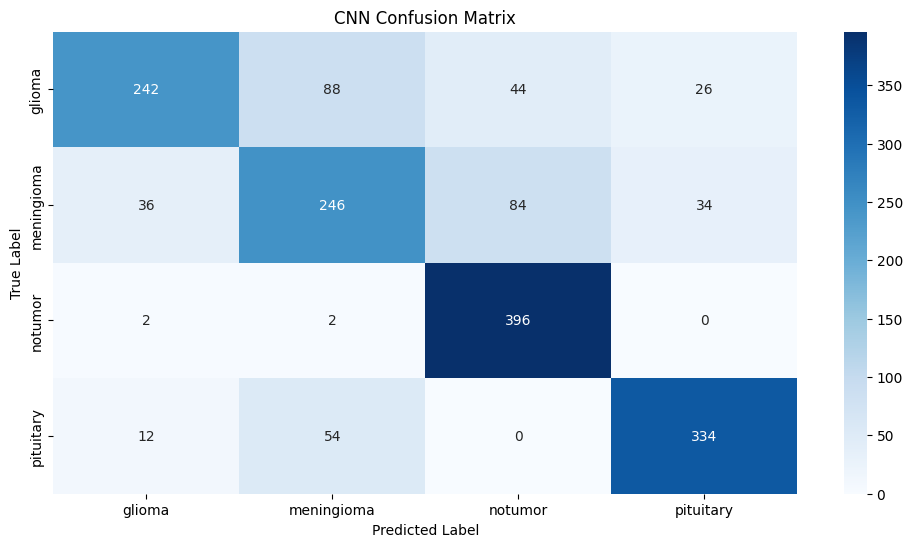

In [40]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("CNN Confusion Matrix")
plt.show()

## 6. ResNet50 Transfer Learning

Import ResNet50 and the layers required to build a classification head on top of the pre-trained network.

In [41]:
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.callbacks import EarlyStopping

### Build the ResNet50 Model

Load ResNet50 with ImageNet weights and exclude its original classification head. Freeze the base model and add a custom classification head for the MRI classes.

In [42]:
# ResNet50 model
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model_resnet = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(num_class, activation='softmax')
])

model_resnet.compile(optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_resnet.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,500 (90.98 MB)

 Trainable params: 262,788 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

### ResNet50 Image Preprocessing

Apply the preprocessing function expected by ResNet50 to the training, validation, and testing datasets.

In [43]:
# Preprocess images for ResNet50
train_ds_resnet = train_ds.map(
    lambda images, labels: (preprocess_input(images), labels)
)

val_ds_resnet = val_ds.map(
    lambda images, labels: (preprocess_input(images), labels)
)

test_ds_resnet = test_ds.map(
    lambda images, labels: (preprocess_input(images), labels)
)

### Train the ResNet50 Model

Train the custom classification head using the prepared datasets and early stopping based on validation loss.

In [44]:
history_resnet = model_resnet.fit(
    train_ds_resnet,
    epochs=10,
    validation_data=val_ds_resnet,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=3,
            restore_best_weights=True)])

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 35s 161ms/step - accuracy: 0.7768 - loss: 0.5818 - val_accuracy: 0.8723 - val_loss: 0.3208
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 130ms/step - accuracy: 0.8687 - loss: 0.3511 - val_accuracy: 0.8929 - val_loss: 0.2745
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 126ms/step - accuracy: 0.8915 - loss: 0.2883 - val_accuracy: 0.9009 - val_loss: 0.2496
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 17s 124ms/step - accuracy: 0.9092 - loss: 0.2502 - val_accuracy: 0.9000 - val_loss: 0.2582
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 126ms/step - accuracy: 0.9121 - loss: 0.2273 - val_accuracy: 0.9312 - val_loss: 0.1976
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 126ms/step - accuracy: 0.9212 - loss: 0.1999 - val_accuracy: 0.9241 - val_loss: 0.2096
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 128ms/step - accuracy: 0.9266 - loss: 0.1838 - val_accuracy: 0.9348 - val_loss: 0.1823
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 128ms/step - accuracy: 0.9230 - loss: 0

### ResNet50 Training History

Plot training and validation accuracy and loss to review the learning behavior of the ResNet50 model.

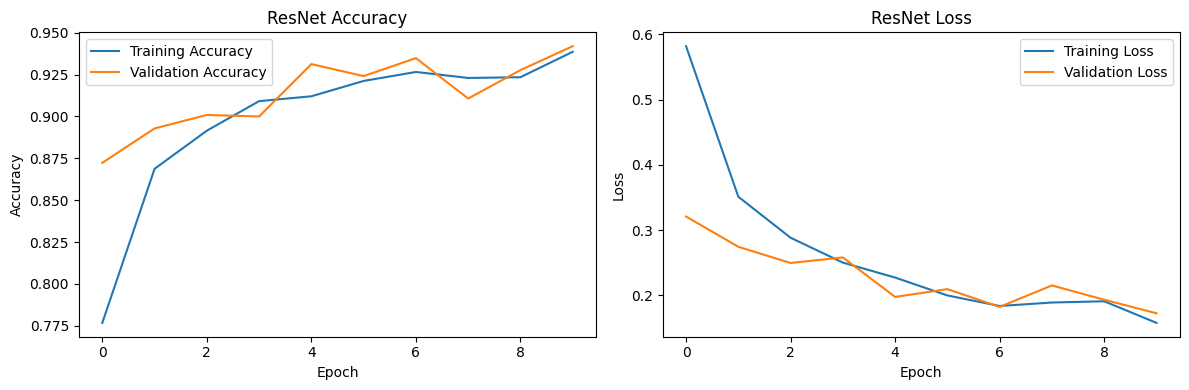

In [45]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_resnet.history["accuracy"], label="Training Accuracy")
plt.plot(history_resnet.history["val_accuracy"], label="Validation Accuracy")
plt.title("ResNet Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_resnet.history["loss"], label="Training Loss")
plt.plot(history_resnet.history["val_loss"], label="Validation Loss")
plt.title("ResNet Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 7. ResNet50 Model Evaluation

Evaluate ResNet50 on the independent testing dataset and display its test loss and accuracy.

In [46]:
resnet_test_loss, resnet_test_accuracy = model_resnet.evaluate(test_ds_resnet)

print("ResNet50 Test Accuracy:", resnet_test_accuracy)
print("ResNet50 Test Loss:", resnet_test_loss)

50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step - accuracy: 0.8881 - loss: 0.4814
ResNet50 Test Accuracy: 0.8881250023841858
ResNet50 Test Loss: 0.48137912154197693


### ResNet50 Classification Report

Generate predictions and review precision, recall, F1-score, and support for each MRI class.

In [47]:
y_true_resnet = np.concatenate([
    labels.numpy() for _, labels in test_ds_resnet
])

y_pred_resnet = np.argmax(
    model_resnet.predict(test_ds_resnet),
    axis=1
)

print(classification_report(
    y_true_resnet,
    y_pred_resnet,
    target_names=class_names
))

50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 104ms/step
              precision    recall  f1-score   support

      glioma       0.97      0.68      0.80       400
  meningioma       0.79      0.88      0.83       400
     notumor       0.90      1.00      0.95       400
   pituitary       0.93      0.99      0.96       400

    accuracy                           0.89      1600
   macro avg       0.90      0.89      0.88      1600
weighted avg       0.90      0.89      0.88      1600



### ResNet50 Confusion Matrix

Visualize the classification results for each class using a confusion matrix.

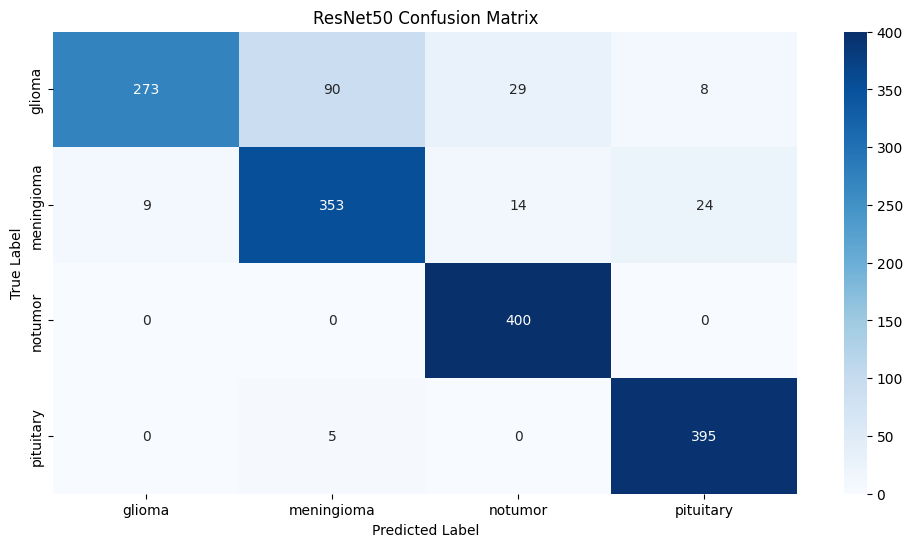

In [48]:
cm_resnet = confusion_matrix(y_true_resnet, y_pred_resnet)

plt.figure(figsize=(12, 6))
sns.heatmap(
    cm_resnet,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("ResNet50 Confusion Matrix")
plt.show()

## 8. Model Comparison

Compare the CNN and ResNet50 models using their test accuracy and test loss.

In [49]:
# Compare model results
comparison = pd.DataFrame({
    'Model': ['CNN', 'ResNet50'],
    'Test Accuracy': [cnn_test_accuracy, resnet_test_accuracy],
    'Test Loss': [cnn_test_loss, resnet_test_loss]
})

display(comparison)


,Model,Test Accuracy,Test Loss
0,CNN,0.761250,0.778457
1,ResNet50,0.888125,0.481379


### Test Accuracy Comparison

Compare the test accuracy achieved by the two models.

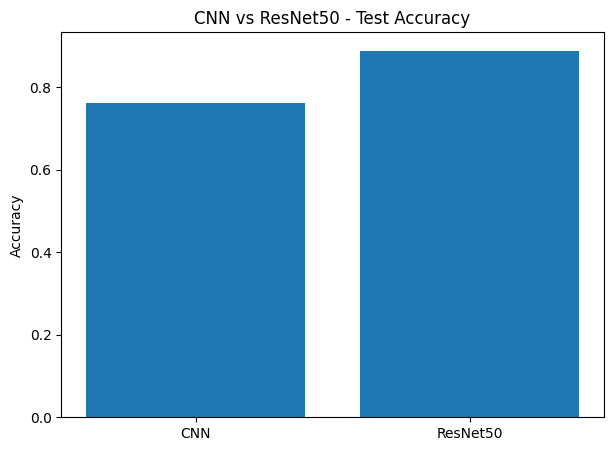

In [50]:
# Accuracy comparison
plt.figure(figsize=(7, 5))
plt.bar(comparison['Model'], comparison['Test Accuracy'])
plt.title('CNN vs ResNet50 - Test Accuracy')
plt.ylabel('Accuracy')
plt.show()


### Test Loss Comparison

Compare the test loss achieved by the two models.

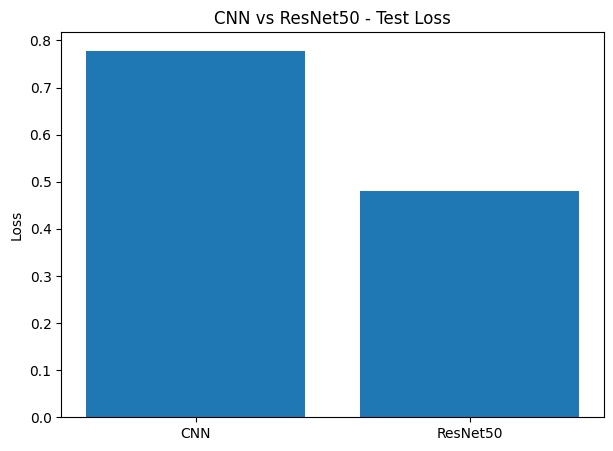

In [51]:
# Loss comparison
plt.figure(figsize=(7, 5))
plt.bar(comparison['Model'], comparison['Test Loss'])
plt.title('CNN vs ResNet50 - Test Loss')
plt.ylabel('Loss')
plt.show()

## 9. Grad-CAM Explainability

Identify the final convolutional layer in ResNet50. Grad-CAM uses gradients from this layer to create a heatmap highlighting image regions that contribute to a prediction.

In [52]:
# Find the last convolutional layer in ResNet50
for layer in base_model.layers[::-1]:
    if isinstance(layer, tf.keras.layers.Conv2D):
        print("Last convolutional layer:", layer.name)
        break

Last convolutional layer: conv5_block3_3_conv


### Generate Grad-CAM Heatmaps

Build the Grad-CAM operation for ResNet50, generate a heatmap for a test MRI image, and display the original image, heatmap, and overlay together with the true and predicted classes.

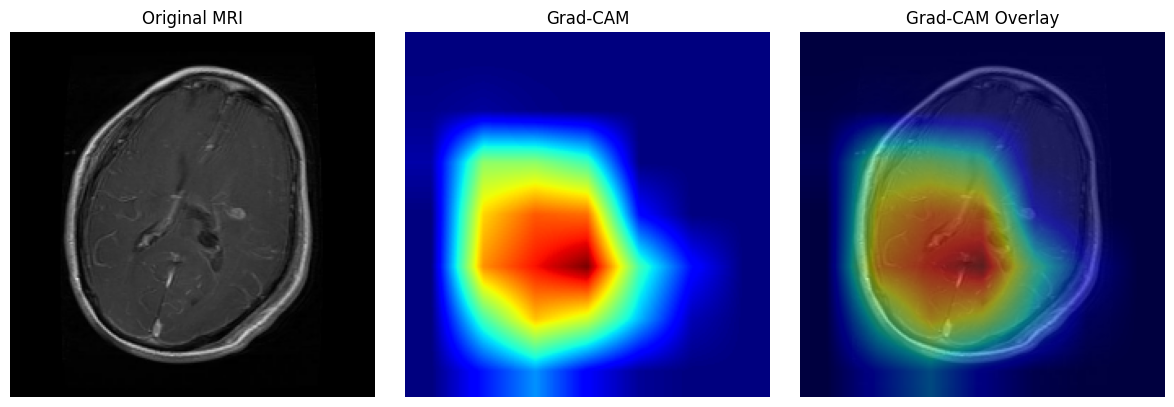

True class: glioma
Predicted class: glioma


In [82]:
# Grad-CAM for Brain Tumor MRI - ResNet50

# Use the last convolutional layer
last_conv_layer_name = "conv5_block3_3_conv"

# Build a Grad-CAM model using the actual model layers
grad_model = tf.keras.Model(
    inputs=base_model.input,
    outputs=[
        base_model.get_layer(last_conv_layer_name).output,
        base_model.output
    ]
)

def grad_cam(image, true_label=None):
    image = tf.cast(image, tf.float32)
    image = tf.expand_dims(image, axis=0)

    # Same preprocessing used for ResNet50
    image = preprocess_input(image)

    with tf.GradientTape() as tape:
        conv_outputs, features = grad_model(image, training=False)

        # Pass features through the classifier layers
        x = features
        for layer in model_resnet.layers[1:]:
            x = layer(x, training=False)

        class_index = tf.argmax(x[0])
        loss = x[:, class_index]

    grads = tape.gradient(loss, conv_outputs)
    weights = tf.reduce_mean(grads, axis=(1, 2))

    cam = tf.reduce_sum(
        conv_outputs * weights[:, tf.newaxis, tf.newaxis, :],
        axis=-1
    )

    cam = tf.nn.relu(cam)[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)

    cam = tf.image.resize(
        cam[..., tf.newaxis], IMG_SIZE
    ).numpy().squeeze()

    return cam, int(class_index.numpy())

# Show one test image
for images, labels in test_ds.take(1):
    image = images[1]
    true_label = int(labels[1].numpy())

    cam, predicted_class = grad_cam(image)

    raw = image.numpy().astype("uint8")

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(raw)
    plt.title("Original MRI")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(cam, cmap="jet")
    plt.title("Grad-CAM")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(raw)
    plt.imshow(cam, cmap="jet", alpha=0.5)
    plt.title("Grad-CAM Overlay")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("True class:", class_names[true_label])
    print("Predicted class:", class_names[predicted_class])


### Grad-CAM Examples Across Classes

Display Grad-CAM visualizations for test images representing the available classes, allowing a visual inspection of the regions emphasized by the model.

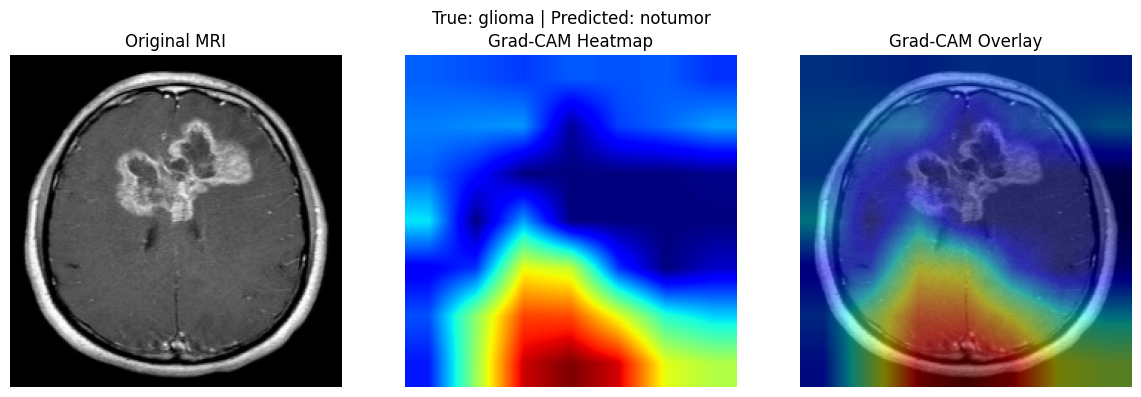

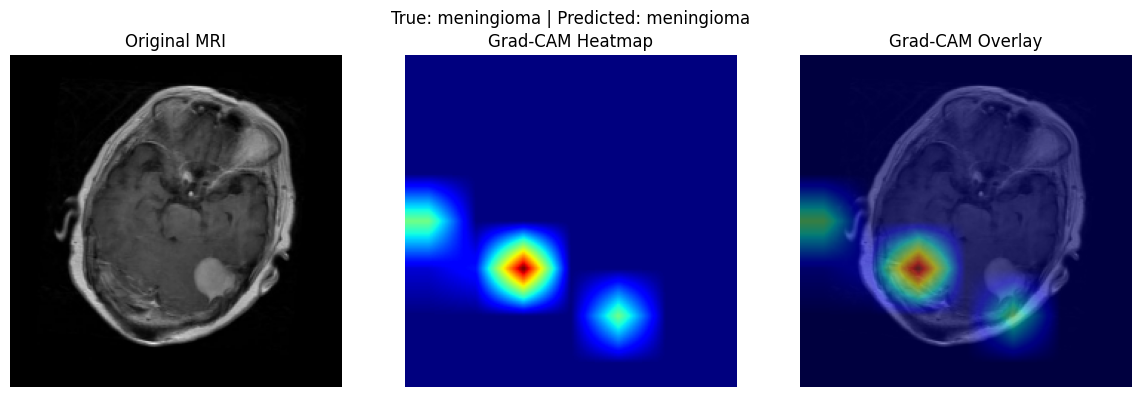

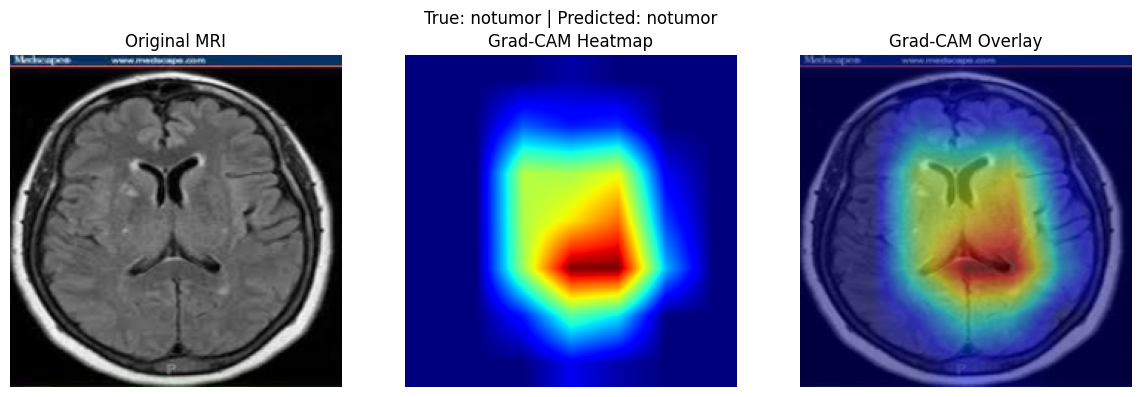

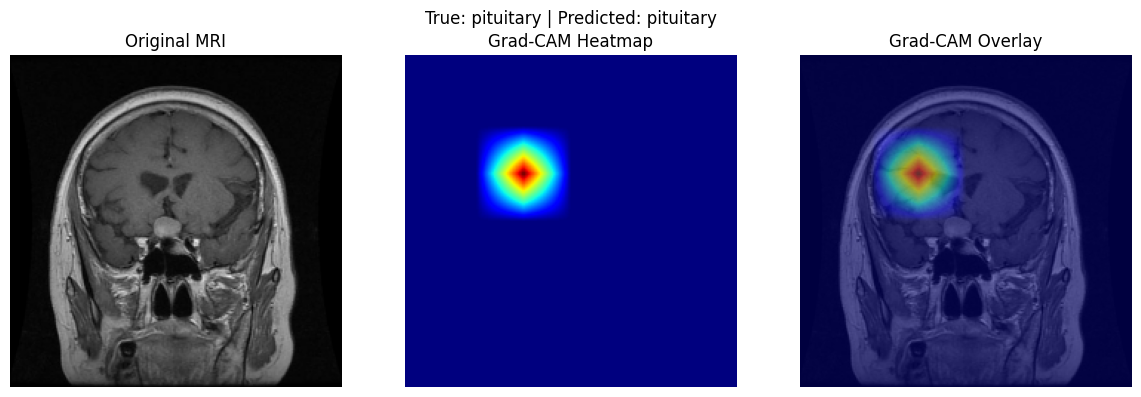

Classes displayed: 4


In [83]:

# Grad-CAM examples from all four classes

shown_classes = set()

for images, labels in test_ds:
    for i in range(len(images)):
        true_label = int(labels[i].numpy())

        if true_label in shown_classes:
            continue

        image = images[i]
        cam, predicted_class = grad_cam(image)
        original = image.numpy().astype("uint8")

        plt.figure(figsize=(12, 4))

        plt.subplot(1, 3, 1)
        plt.imshow(original)
        plt.title("Original MRI")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(cam, cmap="jet")
        plt.title("Grad-CAM Heatmap")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(original)
        plt.imshow(cam, cmap="jet", alpha=0.5)
        plt.title("Grad-CAM Overlay")
        plt.axis("off")

        plt.suptitle(
            f"True: {class_names[true_label]} | "
            f"Predicted: {class_names[predicted_class]}"
        )
        plt.tight_layout()
        plt.show()

        shown_classes.add(true_label)

        if len(shown_classes) == len(class_names):
            break

    if len(shown_classes) == len(class_names):
        break

print("Classes displayed:", len(shown_classes))
